# Conversion Rate Analysis Based on Income, Spending and Age
**Mini Project – Predict Customer Personality to Boost Marketing Campaign**

**Tujuan:**
1. Feature engineering: *conversion rate* (#response / #visit) dan fitur pendukung (umur, jumlah anak, total pengeluaran, total transaksi)
2. Mengelompokkan umur, income, dan spending
3. EDA: melihat jenis customer yang berpotensi lebih besar merespon campaign
4. Menjawab: *Apakah terdapat hubungan yang signifikan antara umur customer dengan conversion rate?*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
PALETTE = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']

## 1. Load Dataset

In [2]:
df = pd.read_csv('marketing_campaign_data.csv')
df = df.drop(columns=['Unnamed: 0'])   # kolom index bawaan
print('Ukuran data:', df.shape)
df.head()

Ukuran data: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntCoke,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,S1,Lajang,58138000.0,0,0,04-09-2012,58,635000,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,S1,Lajang,46344000.0,1,1,08-03-2014,38,11000,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,S1,Bertunangan,71613000.0,0,0,21-08-2013,26,426000,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,S1,Bertunangan,26646000.0,1,0,10-02-2014,26,11000,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,S3,Menikah,58293000.0,1,0,19-01-2014,94,173000,...,5,0,0,0,0,0,0,3,11,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntCoke              2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

In [4]:
df.isna().sum()[df.isna().sum() > 0]

Income    24
dtype: int64

## 2. Data Cleaning
- `Year_Birth` berisi nilai tidak wajar (1893, 1899, 1900 → umur >110 tahun) → dihapus.
- Customer dengan `NumWebVisitsMonth = 0` dihapus karena conversion rate tidak bisa dihitung (pembagian dengan nol).
- `Income` memiliki 24 missing value → tidak diisi, hanya dikecualikan saat analisis yang memakai income.

In [5]:
print('Tahun lahir terkecil:', sorted(df['Year_Birth'])[:5])
print('Customer dengan 0 kunjungan web:', (df['NumWebVisitsMonth'] == 0).sum())

n_awal = len(df)
df = df[(df['Year_Birth'] >= 1940) & (df['NumWebVisitsMonth'] > 0)].copy()
print(f'Data dihapus: {n_awal - len(df)} baris | Sisa: {len(df)} baris')

Tahun lahir terkecil: [1893, 1899, 1900, 1940, 1941]
Customer dengan 0 kunjungan web: 11
Data dihapus: 14 baris | Sisa: 2226 baris


## 3. Feature Engineering

| Fitur | Rumus |
|---|---|
| **Conversion_Rate** | `Response / NumWebVisitsMonth` |
| Age | `2014 - Year_Birth` (data customer tercatat 2012–2014) |
| Total_Children | `Kidhome + Teenhome` |
| Total_Spending | jumlah seluruh kolom `Mnt...` |
| Total_Transactions | `NumWebPurchases + NumCatalogPurchases + NumStorePurchases` |

Karena `Response` bernilai 0/1, conversion rate per customer sebagian besar bernilai 0. Untuk membandingkan antar kelompok, digunakan **conversion rate kelompok = total response ÷ total kunjungan web** pada kelompok tersebut.

In [6]:
df['Conversion_Rate'] = df['Response'] / df['NumWebVisitsMonth']
df['Age'] = 2014 - df['Year_Birth']
df['Total_Children'] = df['Kidhome'] + df['Teenhome']
mnt_cols = ['MntCoke', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
df['Total_Spending'] = df[mnt_cols].sum(axis=1)
df['Total_Transactions'] = df[['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']].sum(axis=1)

print('Rentang Dt_Customer:', pd.to_datetime(df['Dt_Customer'], dayfirst=True).agg(['min', 'max']).dt.date.tolist())
print(f"Conversion rate keseluruhan: {df['Response'].sum() / df['NumWebVisitsMonth'].sum():.2%}")
df[['Conversion_Rate', 'Age', 'Income', 'Total_Children', 'Total_Spending', 'Total_Transactions']].describe().round(3)

Rentang Dt_Customer: [datetime.date(2012, 7, 30), datetime.date(2014, 6, 29)]
Conversion rate keseluruhan: 2.81%


,Conversion_Rate,Age,Income,Total_Children,Total_Spending,Total_Transactions
count,2226.000,2226.000,2.203000e+03,2226.000,2226.000,2226.000
mean,0.044,45.083,5.199269e+07,0.954,603641.959,12.530
std,0.143,11.701,2.476635e+07,0.751,601108.239,7.187
min,0.000,18.000,1.730000e+06,0.000,5000.000,0.000
25%,0.000,37.000,3.519600e+07,0.000,69000.000,6.000
50%,0.000,44.000,5.128700e+07,1.000,395000.000,12.000
75%,0.000,55.000,6.827750e+07,1.000,1039750.000,18.000
max,1.000,74.000,6.666660e+08,3.000,2525000.000,32.000


## 4. Pengelompokan
- **Umur:** Young Adult (<30), Adult (30–44), Middle Age (45–59), Senior (60+)
- **Income & Spending:** dibagi menjadi 4 kelompok sama besar (kuartil): Low, Mid-Low, Mid-High, High

In [7]:
age_labels = ['Young Adult (<30)', 'Adult (30-44)', 'Middle Age (45-59)', 'Senior (60+)']
q_labels = ['Low', 'Mid-Low', 'Mid-High', 'High']

df['Age_Group'] = pd.cut(df['Age'], bins=[0, 29, 44, 59, 100], labels=age_labels)
df['Income_Group'] = pd.qcut(df['Income'], 4, labels=q_labels)
df['Spending_Group'] = pd.qcut(df['Total_Spending'], 4, labels=q_labels)

def cvr_table(col):
    g = df.groupby(col, observed=True).agg(
        Jumlah_Customer=('ID', 'count'),
        Total_Response=('Response', 'sum'),
        Total_Visit=('NumWebVisitsMonth', 'sum'))
    g['CVR (%)'] = (g['Total_Response'] / g['Total_Visit'] * 100).round(2)
    return g

for col in ['Age_Group', 'Income_Group', 'Spending_Group', 'Total_Children']:
    print(f'\n=== {col} ===')
    display(cvr_table(col))


=== Age_Group ===


,Jumlah_Customer,Total_Response,Total_Visit,CVR (%)
Age_Group,,,,
Young Adult (<30),221,36,1172,3.07
Adult (30-44),938,150,5324,2.82
Middle Age (45-59),754,98,3929,2.49
Senior (60+),313,50,1474,3.39



=== Income_Group ===


,Jumlah_Customer,Total_Response,Total_Visit,CVR (%)
Income_Group,,,,
Low,552,58,3872,1.50
Mid-Low,550,69,3490,1.98
Mid-High,550,56,2772,2.02
High,551,150,1643,9.13



=== Spending_Group ===


,Jumlah_Customer,Total_Response,Total_Visit,CVR (%)
Spending_Group,,,,
Low,565,34,3676,0.92
Mid-Low,549,66,3460,1.91
Mid-High,555,66,2725,2.42
High,557,168,2038,8.24



=== Total_Children ===


,Jumlah_Customer,Total_Response,Total_Visit,CVR (%)
Total_Children,,,,
0,628,169,2217,7.62
1,1125,116,6687,1.73
2,420,47,2653,1.77
3,53,2,342,0.58


## 5. Exploratory Data Analysis

### 5.1 Conversion Rate per Umur, Income, Spending, dan Jumlah Anak

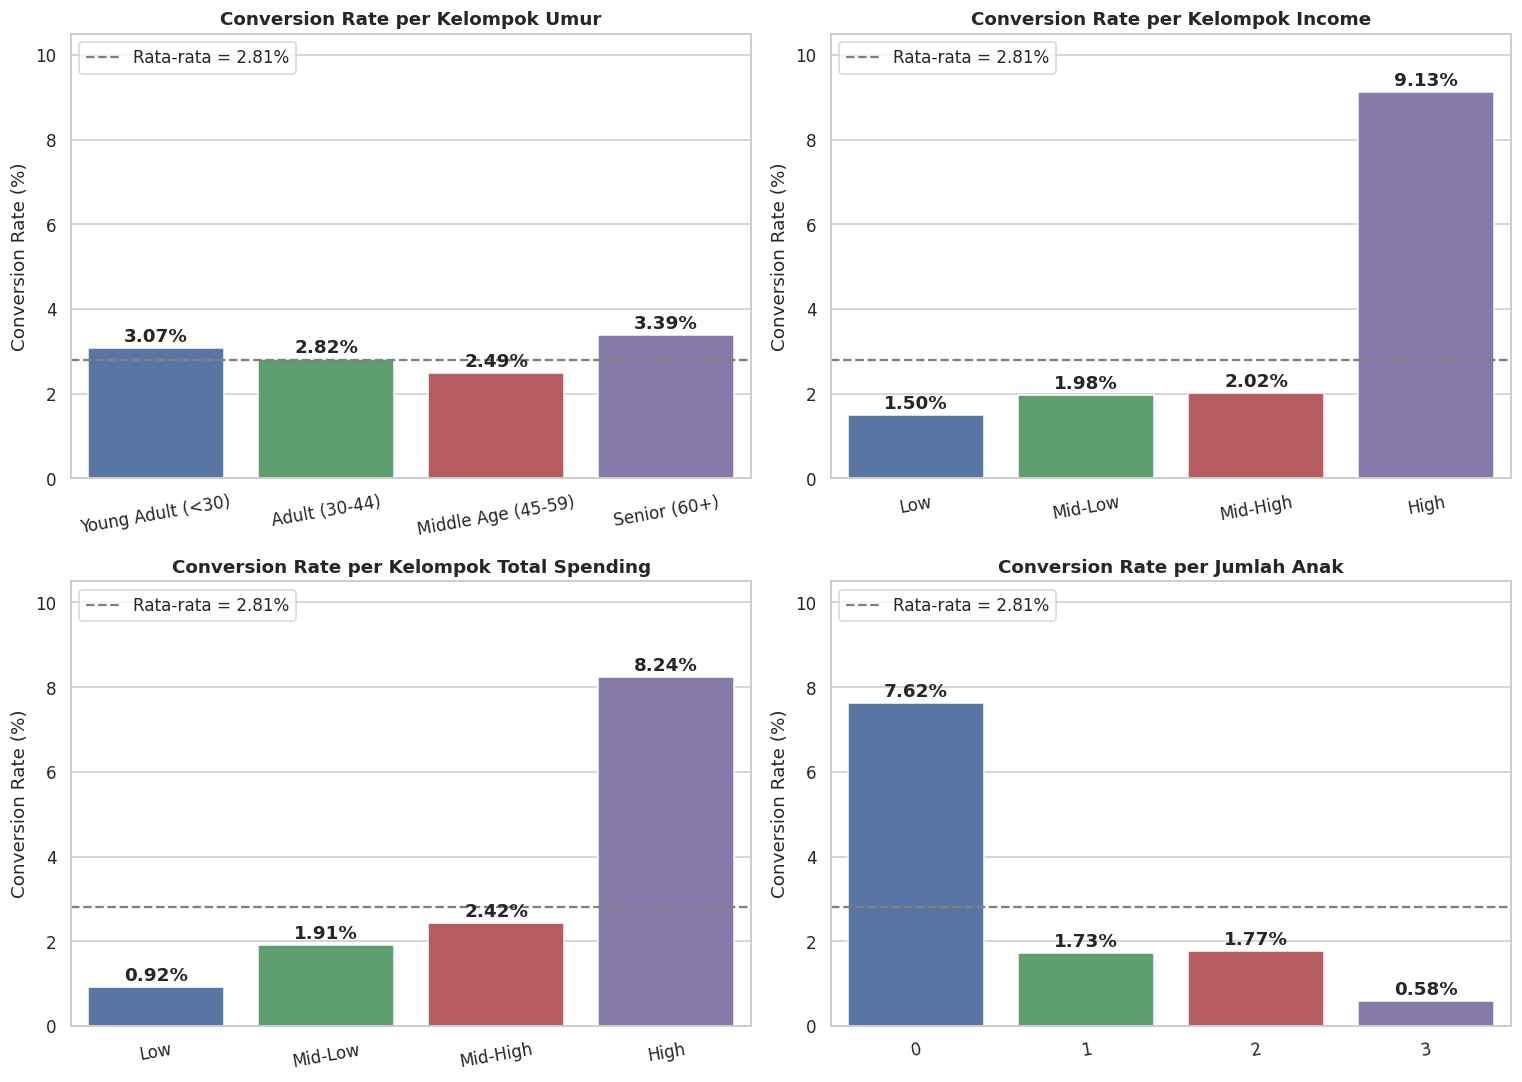

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
overall = df['Response'].sum() / df['NumWebVisitsMonth'].sum() * 100
plots = [('Age_Group', 'Kelompok Umur'), ('Income_Group', 'Kelompok Income'),
         ('Spending_Group', 'Kelompok Total Spending'), ('Total_Children', 'Jumlah Anak')]

for ax, (col, title) in zip(axes.flat, plots):
    t = cvr_table(col)
    sns.barplot(x=t.index.astype(str), y=t['CVR (%)'], palette=PALETTE, ax=ax)
    for i, v in enumerate(t['CVR (%)']):
        ax.text(i, v + 0.15, f'{v:.2f}%', ha='center', fontweight='bold')
    ax.axhline(overall, color='gray', ls='--', label=f'Rata-rata = {overall:.2f}%')
    ax.set_title(f'Conversion Rate per {title}', fontweight='bold')
    ax.set_xlabel(''); ax.set_ylabel('Conversion Rate (%)')
    ax.set_ylim(0, 10.5); ax.legend(loc='upper left')
    ax.tick_params(axis='x', rotation=10)

plt.tight_layout(); plt.savefig('plot_cvr_segmen.png', bbox_inches='tight'); plt.show()

**Interpretasi:**
- **Umur:** conversion rate antar kelompok umur relatif mirip (2.5%–3.4%), tidak ada pola naik/turun yang jelas.
- **Income:** customer dengan income **High** memiliki CVR **9.13%**, sekitar 4–6x lebih tinggi dibanding kelompok lain (1.5%–2.0%).
- **Spending:** pola serupa, kelompok spending **High** mencapai **8.24%**, sedangkan Low hanya 0.92%. CVR naik seiring meningkatnya spending.
- **Jumlah anak:** customer **tanpa anak** memiliki CVR **7.62%**, jauh di atas customer yang punya anak (≤1.8%).

### 5.2 Income vs Spending berdasarkan Respon Campaign

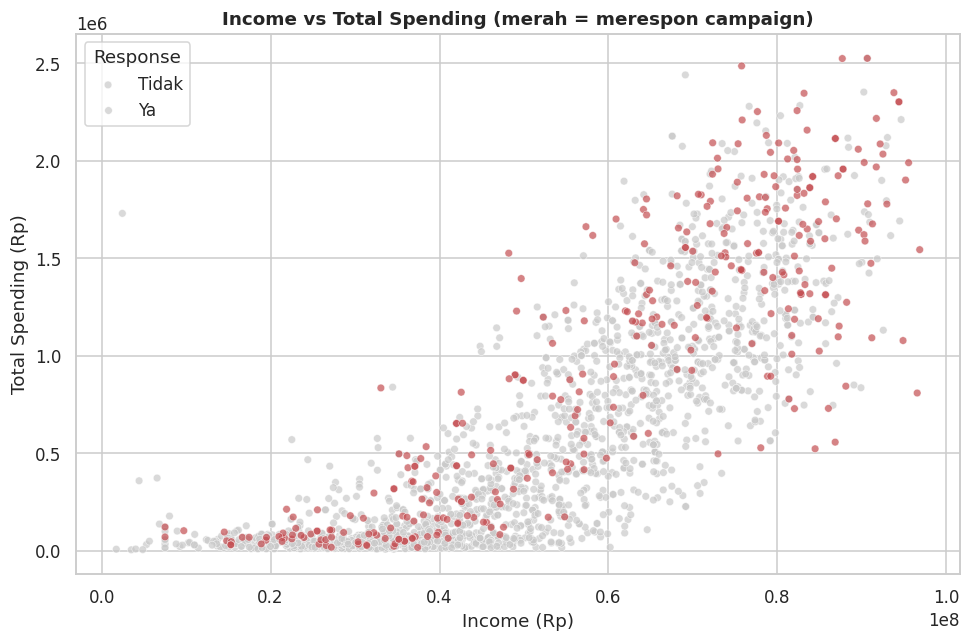

In [9]:
fig, ax = plt.subplots(figsize=(9, 6))
d = df[df['Income'] < df['Income'].quantile(0.995)]
sns.scatterplot(data=d.sort_values('Response'), x='Income', y='Total_Spending', hue='Response',
                palette={0: '#C9C9C9', 1: '#C44E52'}, alpha=0.7, s=25, ax=ax)
ax.set_title('Income vs Total Spending (merah = merespon campaign)', fontweight='bold')
ax.set_xlabel('Income (Rp)'); ax.set_ylabel('Total Spending (Rp)')
ax.legend(title='Response', labels=['Tidak', 'Ya'])
plt.tight_layout(); plt.savefig('plot_income_spending.png', bbox_inches='tight'); plt.show()

**Interpretasi:** titik merah (customer yang merespon) banyak berkumpul di area kanan atas, yaitu customer dengan **income dan spending tinggi**. Customer dengan income dan spending rendah jarang merespon campaign.

### 5.3 Korelasi Conversion Rate dengan Fitur Lain

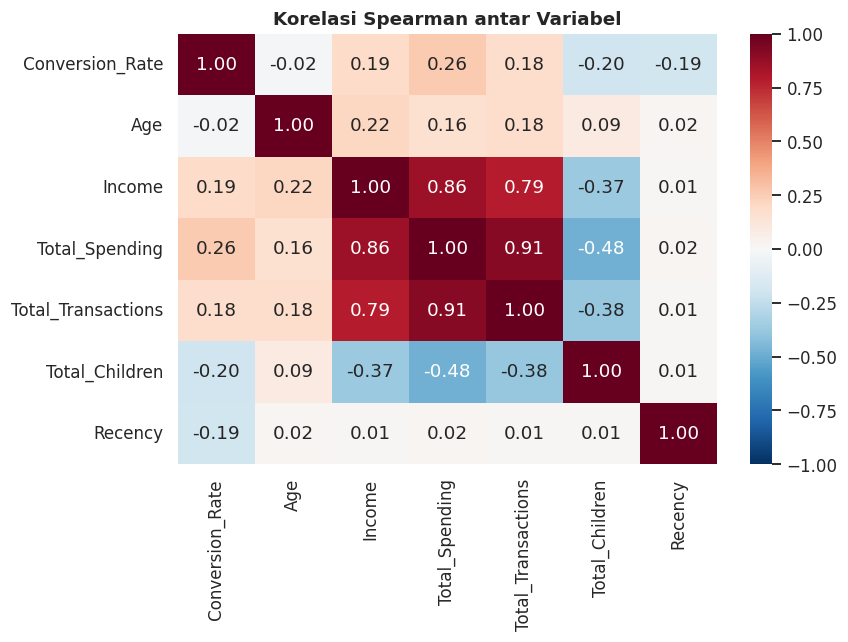

In [10]:
corr_cols = ['Conversion_Rate', 'Age', 'Income', 'Total_Spending', 'Total_Transactions', 'Total_Children', 'Recency']
corr = df[corr_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Korelasi Spearman antar Variabel', fontweight='bold')
plt.tight_layout(); plt.savefig('plot_korelasi.png', bbox_inches='tight'); plt.show()

**Interpretasi:** conversion rate berkorelasi positif dengan **Total_Spending**, **Income**, dan **Total_Transactions**, serta berkorelasi negatif dengan **Total_Children**. Korelasi dengan **Age hampir nol**.

## 6. Uji Statistik: Umur vs Conversion Rate
- **H0:** Tidak ada hubungan antara umur dan conversion rate
- **H1:** Ada hubungan antara umur dan conversion rate

α = 0.05. Digunakan uji non-parametrik karena conversion rate tidak berdistribusi normal (mayoritas bernilai 0).

In [11]:
alpha = 0.05
rows = []
for col in ['Age', 'Income', 'Total_Spending', 'Total_Transactions', 'Total_Children']:
    d = df.dropna(subset=[col])
    rho, p = stats.spearmanr(d[col], d['Conversion_Rate'])
    rows.append([f'Spearman ({col} vs CVR)', rho, p])

groups = [g['Conversion_Rate'] for _, g in df.groupby('Age_Group', observed=True)]
h, p = stats.kruskal(*groups)
rows.append(['Kruskal-Wallis (Age_Group vs CVR)', h, p])

hasil = pd.DataFrame(rows, columns=['Uji', 'Statistik', 'p-value'])
hasil['Signifikan?'] = np.where(hasil['p-value'] < alpha, 'Ya', 'Tidak')
hasil['Statistik'] = hasil['Statistik'].round(3)
hasil['p-value'] = hasil['p-value'].apply(lambda x: f'{x:.2e}')
hasil

,Uji,Statistik,p-value,Signifikan?
0,Spearman (Age vs CVR),-0.020,3.37e-01,Tidak
1,Spearman (Income vs CVR),0.194,4.09e-20,Ya
2,Spearman (Total_Spending vs CVR),0.262,2.49e-36,Ya
3,Spearman (Total_Transactions vs CVR),0.183,3.62e-18,Ya
4,Spearman (Total_Children vs CVR),-0.202,7.04e-22,Ya
5,Kruskal-Wallis (Age_Group vs CVR),3.850,2.78e-01,Tidak


## 7. Kesimpulan & Rekomendasi

**Apakah ada hubungan signifikan antara umur dan conversion rate?**
**Tidak.** Korelasi Spearman umur vs CVR ≈ -0.02 (p ≈ 0.34) dan uji Kruskal-Wallis antar kelompok umur juga tidak signifikan (p ≈ 0.28). H0 gagal ditolak.

**Faktor yang justru berpengaruh signifikan:**
1. **Income** — customer high income: CVR 9.13% vs 1.5–2.0% di kelompok lain
2. **Total spending** — spending high: CVR 8.24% vs 0.92% di spending low
3. **Jumlah anak** — tanpa anak: CVR 7.62% vs ≤1.8% yang punya anak

**Profil customer paling potensial merespon campaign:** berpenghasilan tinggi, pengeluarannya besar, dan tidak memiliki anak — **berapa pun umurnya**.

### Rekomendasi Bisnis
- **Targetkan campaign berdasarkan income, spending, dan status anak**, bukan umur. Ini dapat meningkatkan conversion rate sekaligus menghemat biaya campaign.
- **Buat program eksklusif/premium** (loyalty, early access) untuk segmen high income & high spending.
- **Untuk customer yang memiliki anak**, uji campaign dengan pendekatan berbeda seperti paket keluarga atau promo kebutuhan rumah tangga, karena campaign saat ini kurang relevan bagi mereka.